In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# Locate project root
project_root = Path.cwd()

if not (project_root / "src").is_dir():
    project_root = project_root.parent

assert (project_root / "src").is_dir(), "Project root not found"

sys.path.insert(0, str(project_root))

from src.black_scholes import black_scholes

In [2]:
# Model parameters
S = 100
K = 100
T = 1
r = 0.05
sigma = 0.20

# Calculate Black-Scholes option prices
call_price = black_scholes(S, K, T, r, sigma, "call")
put_price = black_scholes(S, K, T, r, sigma, "put")

print(f"Call Price: {call_price:.4f}")
print(f"Put Price: {put_price:.4f}")


Call Price: 10.4506
Put Price: 5.5735


In [3]:
# Put-call parity validation
lhs = call_price - put_price
rhs = S - K * np.exp(-r * T)

print(f"Left-hand side: {lhs:.8f}")
print(f"Right-hand side: {rhs:.8f}")
print(f"Difference: {abs(lhs - rhs):.12f}")


Left-hand side: 4.87705755
Right-hand side: 4.87705755
Difference: 0.000000000000


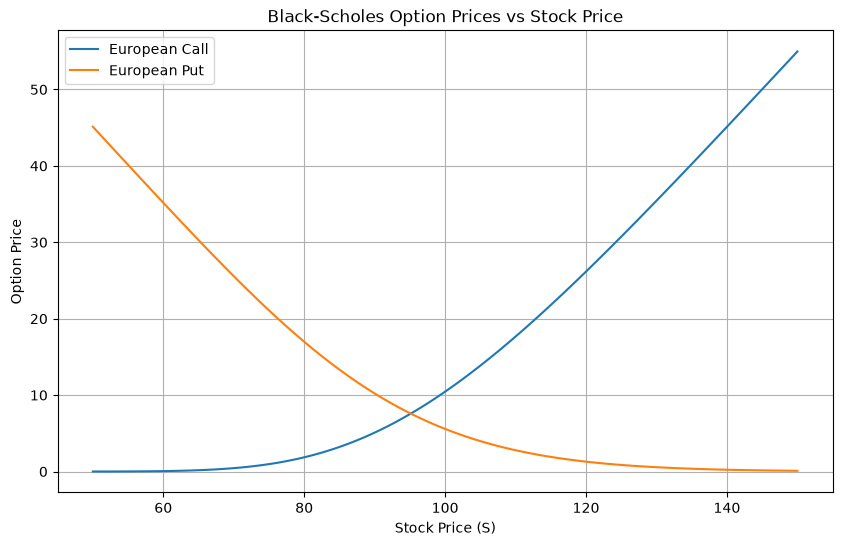

In [4]:
#Gamma
# Stock price range
S_values = np.linspace(50, 150, 100)

# Calculate option prices
call_prices = black_scholes(S_values, K, T, r, sigma, "call")
put_prices = black_scholes(S_values, K, T, r, sigma, "put")

# Plot
plt.figure(figsize=(10, 6))

plt.plot(S_values, call_prices, label="European Call")
plt.plot(S_values, put_prices, label="European Put")

plt.xlabel("Stock Price (S)")
plt.ylabel("Option Price")
plt.title("Black-Scholes Option Prices vs Stock Price")

plt.legend()
plt.grid(True)
plt.show()

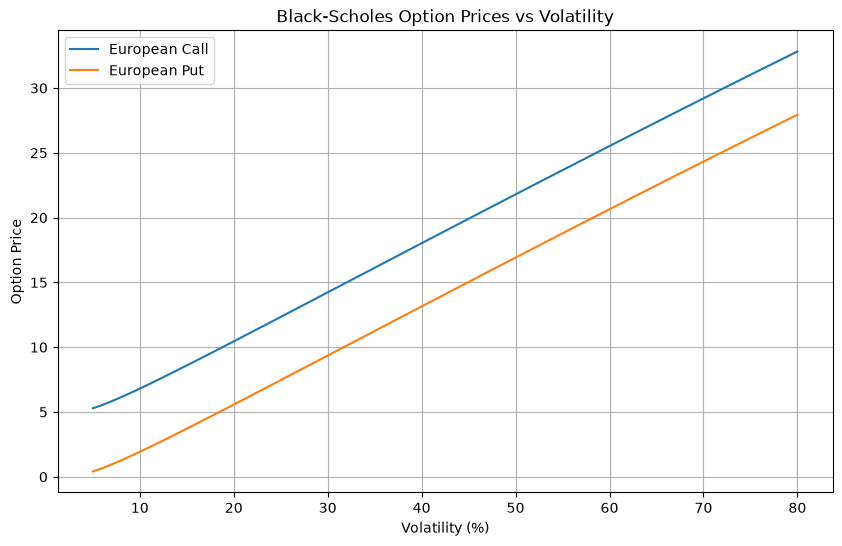

In [5]:
#Vega
# Volatility range: 5% to 80%
sigma_values = np.linspace(0.05, 0.80, 100)

# Calculate option prices
call_vol = black_scholes(S, K, T, r, sigma_values, "call")
put_vol = black_scholes(S, K, T, r, sigma_values, "put")

# Plot
plt.figure(figsize=(10, 6))

plt.plot(sigma_values * 100, call_vol, label="European Call")
plt.plot(sigma_values * 100, put_vol, label="European Put")

plt.xlabel("Volatility (%)")
plt.ylabel("Option Price")
plt.title("Black-Scholes Option Prices vs Volatility")

plt.legend()
plt.grid(True)
plt.show()

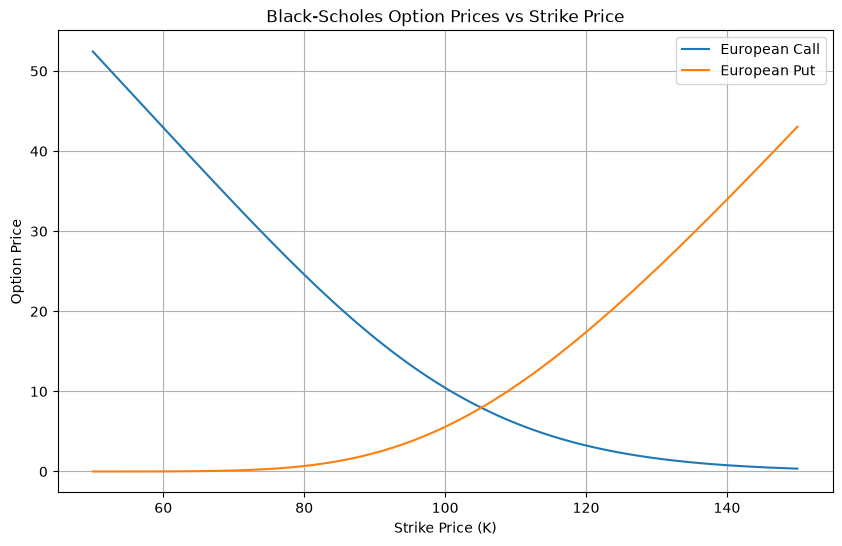

In [6]:
# Strike price range
K_values = np.linspace(50, 150, 100)

# Calculate option prices
call_strike = black_scholes(S, K_values, T, r, sigma, "call")
put_strike = black_scholes(S, K_values, T, r, sigma, "put")

# Plot
plt.figure(figsize=(10, 6))

plt.plot(K_values, call_strike, label="European Call")
plt.plot(K_values, put_strike, label="European Put")

plt.xlabel("Strike Price (K)")
plt.ylabel("Option Price")
plt.title("Black-Scholes Option Prices vs Strike Price")

plt.legend()
plt.grid(True)
plt.show()


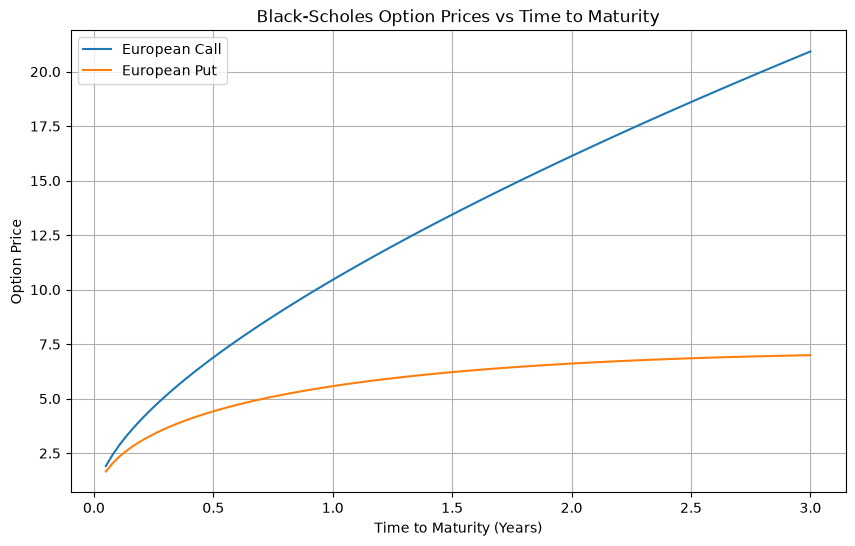

In [7]:
#Theta
# Time to maturity range: 0.05 to 3 years
T_values = np.linspace(0.05, 3, 100)

# Calculate option prices
call_maturity = black_scholes(S, K, T_values, r, sigma, "call")
put_maturity = black_scholes(S, K, T_values, r, sigma, "put")

# Plot
plt.figure(figsize=(10, 6))

plt.plot(T_values, call_maturity, label="European Call")
plt.plot(T_values, put_maturity, label="European Put")

plt.xlabel("Time to Maturity (Years)")
plt.ylabel("Option Price")
plt.title("Black-Scholes Option Prices vs Time to Maturity")

plt.legend()
plt.grid(True)
plt.show()


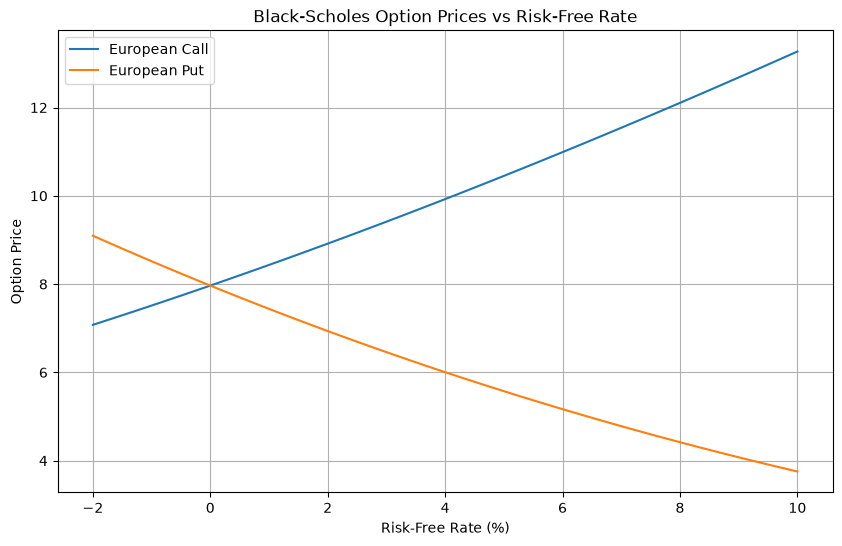

In [8]:
#Rho
# Risk-free rate range: -2% to 10%
r_values = np.linspace(-0.02, 0.10, 100)

# Calculate option prices
call_rates = black_scholes(S, K, T, r_values, sigma, "call")
put_rates = black_scholes(S, K, T, r_values, sigma, "put")

# Plot
plt.figure(figsize=(10, 6))

plt.plot(r_values * 100, call_rates, label="European Call")
plt.plot(r_values * 100, put_rates, label="European Put")

plt.xlabel("Risk-Free Rate (%)")
plt.ylabel("Option Price")
plt.title("Black-Scholes Option Prices vs Risk-Free Rate")

plt.legend()
plt.grid(True)
plt.show()


In [9]:
# Create requirements.txt
requirements = """numpy
scipy
matplotlib
pandas
pytest
jupyter
"""

(project_root / "requirements.txt").write_text(requirements)

print("requirements.txt created successfully.")


requirements.txt created successfully.


In [10]:
readme = """# Option Pricing and Volatility Modeling in Python

A quantitative finance project exploring European option pricing,
numerical simulation, and volatility modeling.

## Implemented Models

### 1. Black-Scholes-Merton
- European call and put pricing
- Put-call parity validation
- Sensitivity analysis
- Input validation and boundary cases
- Automated tests using pytest

## Planned Extensions

- Monte Carlo option pricing
- Confidence intervals and convergence analysis
- Analytical and numerical Greeks
- Implied volatility estimation
- Volatility smile analysis

## Technologies

Python, NumPy, SciPy, Matplotlib, pandas, pytest.

## Assumptions

The initial Black-Scholes implementation assumes a
non-dividend-paying underlying, constant volatility,
constant risk-free interest rate, and European exercise.
"""

(project_root / "README.md").write_text(readme)

print("README.md created successfully.")


README.md created successfully.
